<a href="https://colab.research.google.com/github/kingdragonlord/Numpy-Pandas-Basics/blob/main/Numpy_%26_Pandas_Basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Numpy & Pandas Basics


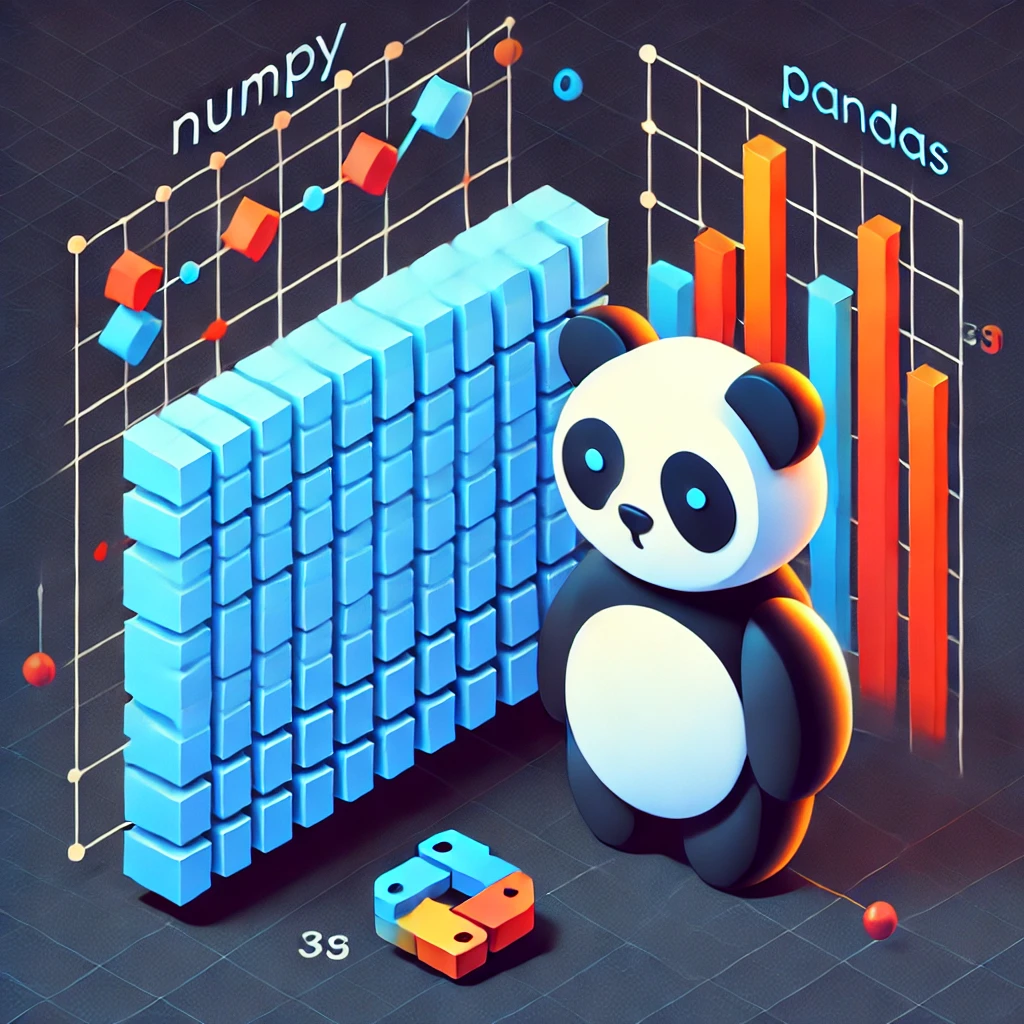

## Exercises

 1. Implement a function to perform Z-score normalization (standardization) on each column of a 2D array. Use (x - mean) / std where mean and std are calculated per column. Ensure that the values of the array provided to the function are not modified, and include parameters to optionally return the mean and standard deviations of the columns.

In [ ]:
import numpy as np

a = np.random.randint(low=1, high=100, size=(4,4))
print(a)

def z_score_normalization(n, return_means_stds=False):
    means = np.mean(n, axis=0)
    stds = np.std(n, axis=0)
    normalized = (n - means) / stds
    if return_means_stds:
        return  normalized, means, stds

    return normalized

z_score_normalization(a, return_means_stds=True)


[[66 28 42  5]
 [83 80 81 72]
 [70 50 33  6]
 [ 8  1 81 46]]


(array([[ 0.32074629, -0.40512725, -0.78474987, -0.96332011],
        [ 0.91022597,  1.38777634,  0.98946723,  1.40521006],
        [ 0.45944739,  0.35340888, -1.19418459, -0.92796891],
        [-1.69041965, -1.33605797,  0.98946723,  0.48607895]]),
 array([56.75, 39.75, 59.25, 32.25]),
 array([28.8389927 , 29.00323258, 21.98152633, 28.28758562]))

2. Write a function which, given a 2d array and a scalar, returns a 1D array containing the closest value from each column to that given scalar.

In [ ]:
def closest_in_columns(n, scalar):
    closest_values = []

    for col in range(n.shape[1]):
        column = n[:, col]
        closest_index = np.abs(column - scalar).argmin()
        closest_values.append(column[closest_index])
    return closest_values

closest_in_columns(a, 50)

[66, 50, 42, 46]

In [ ]:
def closest_in_column(n, scalar):
  closest_indices = np.argmin(np.abs(n - scalar), axis=0)
  closest_values = n[closest_indices, range(n.shape[1])]
  return closest_values

closest_in_column(a, 50)

array([66, 50, 42, 46])

3. Implement a function that takes a 2D array A as input and calculates the pairwise distances between all samples in the array.

In [ ]:
def pairwise_distances(A):
    distances = np.zeros((A.shape[0], A.shape[0]))
    for i in range(A.shape[0]):
        for j in range(A.shape[0]):
            distances[i, j] = np.linalg.norm(A[i] - A[j])
    return distances

pairwise_distances(a)

array([[  0.        ,  94.88413988,  24.12467616,  85.41077215],
       [ 94.88413988,   0.        ,  87.91473142, 111.99107107],
       [ 24.12467616,  87.91473142,   0.        , 100.74224536],
       [ 85.41077215, 111.99107107, 100.74224536,   0.        ]])

In [ ]:
def pairwise_distance(A):
  distances = np.sqrt(((A[:, np.newaxis] - A[np.newaxis, :])**2).sum(axis=2))
  return distances

pairwise_distance(a)

array([[  0.        ,  94.88413988,  24.12467616,  85.41077215],
       [ 94.88413988,   0.        ,  87.91473142, 111.99107107],
       [ 24.12467616,  87.91473142,   0.        , 100.74224536],
       [ 85.41077215, 111.99107107, 100.74224536,   0.        ]])

4. Given a 2D array `A`, write a function that computes the sum of absolute values of all elements along a given axis. Your function should be implemented using broadcasting and take in an optional `axis` parameter (which determines if you perform the operation along axis 0 or axis 1).

In [ ]:
def sum_absolute_values(A, axis=None):
    abs_values = np.abs(A)
    result = np.sum(abs_values, axis=axis)
    return result

sum_absolute_values(a, axis=1)

array([141, 316, 159, 136])

In [ ]:
def sum_absolute_value(A, axis=None):
  return np.abs(A).sum(axis=axis)

sum_absolute_value(a, axis=1)

array([141, 316, 159, 136])

5. Given a 2D array `A`, implement a function which retrieves the second smallest element from each row.

In [ ]:
def second_smallest_element(A):
  sorted_rows = np.sort(A, axis=1)
  second_smallest = sorted_rows[:, 1]
  return second_smallest

second_smallest_element(a)


array([28, 80, 33,  8])

In [ ]:
def second_smallest_element1(A):
  second_smallest_elements = []
  for row in A:
    sorted_row = np.sort(row)
    second_smallest_elements.append(sorted_row[1])
  return second_smallest_elements

second_smallest_element1(a)

[28, 80, 33, 8]

6. Create a 2D array of random integers between 1 and 10, with shape (30, 20). For each row, find the unique elements using np.unique, and then use boolean indexing to return all elements in each row that are not unique.

In [ ]:
b = np.random.randint(low=1, high=10, size=(30,20))
print(b)

def non_unique_elements(A):
  results = []
  for row in A:
    unique_elements, counts = np.unique(row, return_counts=True)
    non_unique_mask = counts > 1
    non_unique_elements = row[np.isin(row, unique_elements[non_unique_mask])]
    results.append(non_unique_elements)
  return results

non_unique_elements(b)


[[2 6 8 8 1 7 7 2 2 1 6 2 4 5 7 6 9 2 8 3]
 [9 6 6 3 2 5 3 2 6 2 9 4 9 3 9 3 1 1 9 5]
 [3 5 7 7 9 3 5 2 9 6 1 5 9 3 4 1 8 8 7 1]
 [1 2 3 2 4 9 4 1 2 4 9 4 8 9 7 3 4 7 2 8]
 [4 9 8 6 5 7 9 4 3 3 1 9 9 2 8 1 6 7 6 3]
 [2 5 5 2 3 7 8 5 1 2 8 4 1 2 5 2 8 9 1 6]
 [2 3 5 7 3 1 1 2 1 3 9 6 6 9 3 4 6 9 4 7]
 [5 7 2 1 7 6 5 9 5 5 5 5 4 8 8 3 7 9 6 6]
 [4 6 6 2 7 6 6 5 9 8 5 6 7 9 6 7 7 6 7 1]
 [7 2 7 9 5 1 3 1 7 7 1 2 3 9 1 9 4 8 6 2]
 [3 8 5 2 4 2 1 5 9 5 6 9 8 3 3 1 2 3 9 4]
 [4 8 1 4 1 5 7 1 3 3 3 1 9 3 6 6 3 6 7 9]
 [6 1 9 9 2 9 9 7 4 3 5 4 8 4 7 6 2 9 3 8]
 [8 3 5 2 1 4 8 6 5 4 8 6 2 5 4 1 4 5 4 9]
 [7 7 9 4 3 8 4 9 1 3 4 4 1 3 9 2 3 3 8 7]
 [9 9 9 1 3 1 7 4 1 9 3 9 4 3 1 8 5 2 2 1]
 [9 4 8 7 3 3 4 4 7 9 8 7 3 2 5 2 8 1 1 5]
 [1 2 1 9 2 9 9 9 8 1 2 8 4 2 9 3 5 6 6 6]
 [6 7 1 5 6 4 3 5 9 7 4 2 2 6 5 8 4 9 1 5]
 [4 5 4 2 5 3 4 3 9 5 7 5 5 3 2 8 9 7 4 7]
 [5 2 8 8 3 3 3 9 8 9 2 8 3 7 1 8 9 9 8 6]
 [7 2 1 4 2 1 8 8 8 1 9 5 5 7 7 4 6 3 7 8]
 [4 1 6 1 6 1 8 6 3 4 4 4 3 3 8 2 3 3 1 7]
 [5 5 1 4 6

[array([2, 6, 8, 8, 1, 7, 7, 2, 2, 1, 6, 2, 7, 6, 2, 8]),
 array([9, 6, 6, 3, 2, 5, 3, 2, 6, 2, 9, 9, 3, 9, 3, 1, 1, 9, 5]),
 array([3, 5, 7, 7, 9, 3, 5, 9, 1, 5, 9, 3, 1, 8, 8, 7, 1]),
 array([1, 2, 3, 2, 4, 9, 4, 1, 2, 4, 9, 4, 8, 9, 7, 3, 4, 7, 2, 8]),
 array([4, 9, 8, 6, 7, 9, 4, 3, 3, 1, 9, 9, 8, 1, 6, 7, 6, 3]),
 array([2, 5, 5, 2, 8, 5, 1, 2, 8, 1, 2, 5, 2, 8, 1]),
 array([2, 3, 7, 3, 1, 1, 2, 1, 3, 9, 6, 6, 9, 3, 4, 6, 9, 4, 7]),
 array([5, 7, 7, 6, 5, 9, 5, 5, 5, 5, 8, 8, 7, 9, 6, 6]),
 array([6, 6, 7, 6, 6, 5, 9, 5, 6, 7, 9, 6, 7, 7, 6, 7]),
 array([7, 2, 7, 9, 1, 3, 1, 7, 7, 1, 2, 3, 9, 1, 9, 2]),
 array([3, 8, 5, 2, 4, 2, 1, 5, 9, 5, 9, 8, 3, 3, 1, 2, 3, 9, 4]),
 array([4, 1, 4, 1, 7, 1, 3, 3, 3, 1, 9, 3, 6, 6, 3, 6, 7, 9]),
 array([6, 9, 9, 2, 9, 9, 7, 4, 3, 4, 8, 4, 7, 6, 2, 9, 3, 8]),
 array([8, 5, 2, 1, 4, 8, 6, 5, 4, 8, 6, 2, 5, 4, 1, 4, 5, 4]),
 array([7, 7, 9, 4, 3, 8, 4, 9, 1, 3, 4, 4, 1, 3, 9, 3, 3, 8, 7]),
 array([9, 9, 9, 1, 3, 1, 4, 1, 9, 3, 9, 4, 3, 1, 2, 2, 1]

7. In this problem you will will use the Titanic dataset to predict passenger survival. The Titanic dataset is a classic dataset used for binary classification. The dataset includes missing values, particularly in the Age and Cabin columns. This task will involve using a KNN classifier to make predictions and handling the data with pandas.

The following code downloads the dataset for you, and saves it as 'titanic.csv'.

In [ ]:
!wget https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv -O titanic.csv

--2024-10-04 04:03:27--  https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 60302 (59K) [text/plain]
Saving to: ‘titanic.csv’

titanic.csv         100%[===================>]  58.89K  --.-KB/s    in 0.02s   

2024-10-04 04:03:27 (2.75 MB/s) - ‘titanic.csv’ saved [60302/60302]



Load the Titanic dataset using pandas:

In [ ]:
import pandas as pd
df = pd.read_csv('titanic.csv')

 Explore the dataset using pandas functions such as head(), info(), and describe().

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Impute missing `Age` values using the median or mean age.

In [ ]:
def impute_missing_age(df):
    median_age = df['Age'].median()
    df['Age'] = df['Age'].fillna(median_age)
    return median_age

impute_missing_age(df)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Drop the `Cabin` column, as it contains too many missing values to be useful.

In [ ]:
df.drop('Cabin', axis=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


Fill missing `Embarked` values with the mode (most frequent value).

In [ ]:
def impute_embarked_values(df):
  mode_embarked = df['Embarked'].mode()[0]
  df['Embarked'] = df['Embarked'].fillna(mode_embarked)
  return mode_embarked

impute_embarked_values(df)

'S'

Check to see if there are any missing values in your dataframe:

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


Use pandas to convert categorical variables into numerical values using one-hot encoding as follows:

In [ ]:
df_encoded = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)
df_encoded.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_male,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,True,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,False,False,True
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,True,False,True


In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Age          891 non-null    float64
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Ticket       891 non-null    object 
 8   Fare         891 non-null    float64
 9   Sex_male     891 non-null    bool   
 10  Embarked_Q   891 non-null    bool   
 11  Embarked_S   891 non-null    bool   
dtypes: bool(3), float64(2), int64(5), object(2)
memory usage: 65.4+ KB


Select relevant features from the dataset that you will use in your model.

In [ ]:
features = [
    'Pclass', 'Sex_male', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S'
]

Read the documentation for `pd.get_dummies` and describe how it works in your own words:

**pd.get_dummies is a way to convert categorical variables into numerical representation known as one-hot encoding. These variables are saved as the name of the variable followed by the data for example, in Sex, it would split into Sex_male and Sex_female and then doing boolean indexing**

Split the data into training and testing sets using a 20% split for testing.

In [ ]:
X = df_encoded[features]
y = df_encoded['Survived']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Use your function from Exercise 1 to normalize the columns of `X_train`, and set the parameters to return the means and standard deviations for the columns of `X_train`. Then, normalize `X_test` using the means and standard deviations of `X_train`.

In [ ]:
X_train_normalized, X_train_means, X_train_stds = z_score_normalization(X_train, return_means_stds=True)
X_test_normalized = (X_test - X_train_means) / X_train_stds

Instantiate a KNN Classifier and fit it to the dataset:

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_normalized, y_train)


KNeighborsClassifier()

Evaluate your model's performance. Check the accuracy and create a Confusion matrix for your model's predictions on the test set.

0.8044692737430168

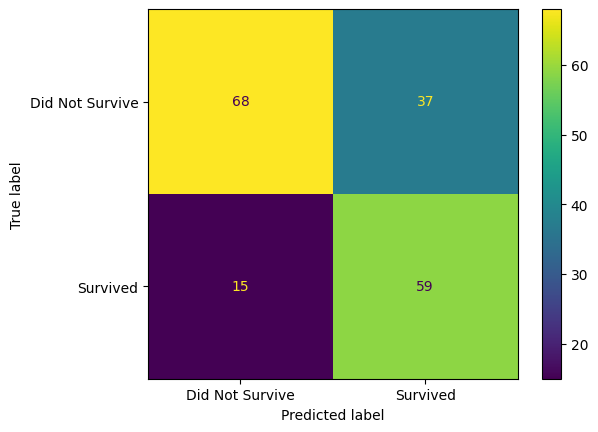

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    estimator=knn,
    X=X_test,
    y=y_test,
    display_labels=['Did Not Survive', 'Survived']
)

predictions = knn.predict(X_test_normalized)
accuracy_score(predictions, y_test)